In [2]:
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.ticker import ScalarFormatter

formatter = ScalarFormatter(useMathText=True)
formatter.set_scientific(True)
formatter.set_powerlimits((0, 0))

%config InlineBackend.figure_format = 'retina'
cmap = plt.cm.viridis
cmap2 = plt.cm.twilight
rng = np.random.default_rng(seed=12345)   # PCG64 by default
cm = 1 / 2.54


# Hippocampal Data

### Load data


In [3]:
n_channels = 31
fs = 1250 # Hz

path = '../Hippocampal/data/'
file = 'ec013.527.eeg'
x = np.fromfile(path+file, dtype=np.int16)
x = x.reshape(-1, n_channels)

signal = x[:,5]      # sixth channel
time = np.arange(len(signal))/fs
print(time.shape[0])

1325125


### Plot dense data

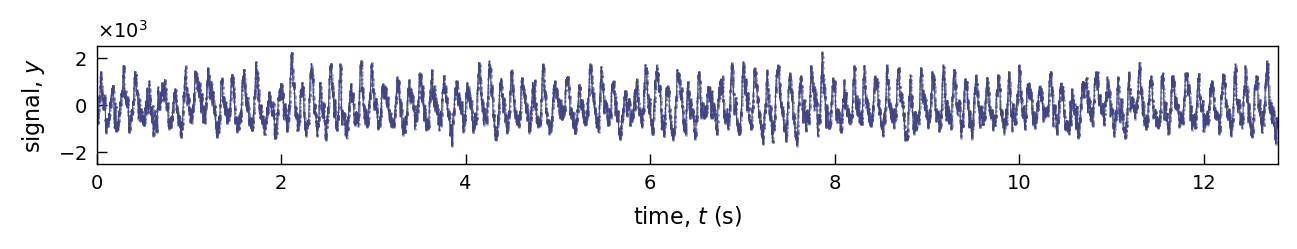

In [4]:
imin = 10000
istep = 1
Nmax = 16000
imax = imin + istep*Nmax

tk = time[imin:imax:istep] - time[imin]
yk = signal[imin:imax:istep]
dtmin = np.diff(tk).mean()

# fixed axis geometry
ax_h = 1.5 * cm
ax_w = 15 * cm

left = 1.5 * cm
bottom = 1.5 * cm
right = 0.5 * cm
top = 0.5 * cm

fig_w = left + ax_w + right
fig_h = bottom + ax_h + top

fig = plt.figure(figsize=(fig_w, fig_h))

ax = fig.add_axes([
    left / fig_w,
    bottom / fig_h,
    ax_w / fig_w,
    ax_h / fig_h
])

ax.plot(tk, yk,  '-', c=cmap(0.2), lw=0.4)
ax.plot(tk, yk,  '.', alpha=0.5, c=cmap(0.2), mew=0, ms=2)
ax.set_xlim(tk[0], tk[-1])
ax.set_ylim(-2500, 2500)
ax.yaxis.set_major_formatter(formatter)
ax.yaxis.get_offset_text().set_fontsize(7)

ax.set_xlabel('time, $t$ (s)', fontsize=8)
ax.set_ylabel('signal, $y$', fontsize=8)

# Set tick label fonts to 7 pt, tick mark widths to 0.5 pt, and ticks pointing inward
ax.tick_params(axis='both', which='major', labelsize=7, width=0.5, direction='in')
ax.tick_params(axis='both', which='minor', labelsize=7, width=0.5, direction='in')

# Set the width of the frame (all spines) to 0.5 pt
for spine in ax.spines.values():
    spine.set_linewidth(0.5)

plt.savefig('plots/HippocampalTrace.pdf')

# FFT Analysis

Subtract the sample mean to remove the zero-frequency offset, then compute the one-sided FFT and its power spectral density.

In [5]:
centered_signal = yk.astype(float) - yk.mean()
sampling_frequency = 1 / dtmin
fft_values = np.fft.rfft(centered_signal)
frequencies = np.fft.rfftfreq(centered_signal.size, d=dtmin)

# One-sided power spectral density (signal units squared per Hz).
power_spectrum = np.abs(fft_values) ** 2 / (sampling_frequency * centered_signal.size)
power_spectrum[1:-1] *= 2

peak_index = 1 + np.argmax(power_spectrum[1:])
peak_frequency = frequencies[peak_index]
omega_fft = 2 * np.pi * peak_frequency

parameter_estimates_path = '../Hippocampal/data/parameter_estimates_good.npz'
with np.load(parameter_estimates_path) as parameter_data:
    map_estimate = parameter_data['map_estimate']
    parameter_names = parameter_data['parameter_names']

omega_index = np.flatnonzero(parameter_names == 'omega').item()
omega_map = map_estimate[omega_index]
map_frequency = omega_map / (2 * np.pi)

print(f'FFT peak frequency: {peak_frequency:.3f} Hz')
print(f'MAP frequency:      {map_frequency:.3f} Hz')

FFT peak frequency: 8.359 Hz
MAP frequency:      8.255 Hz


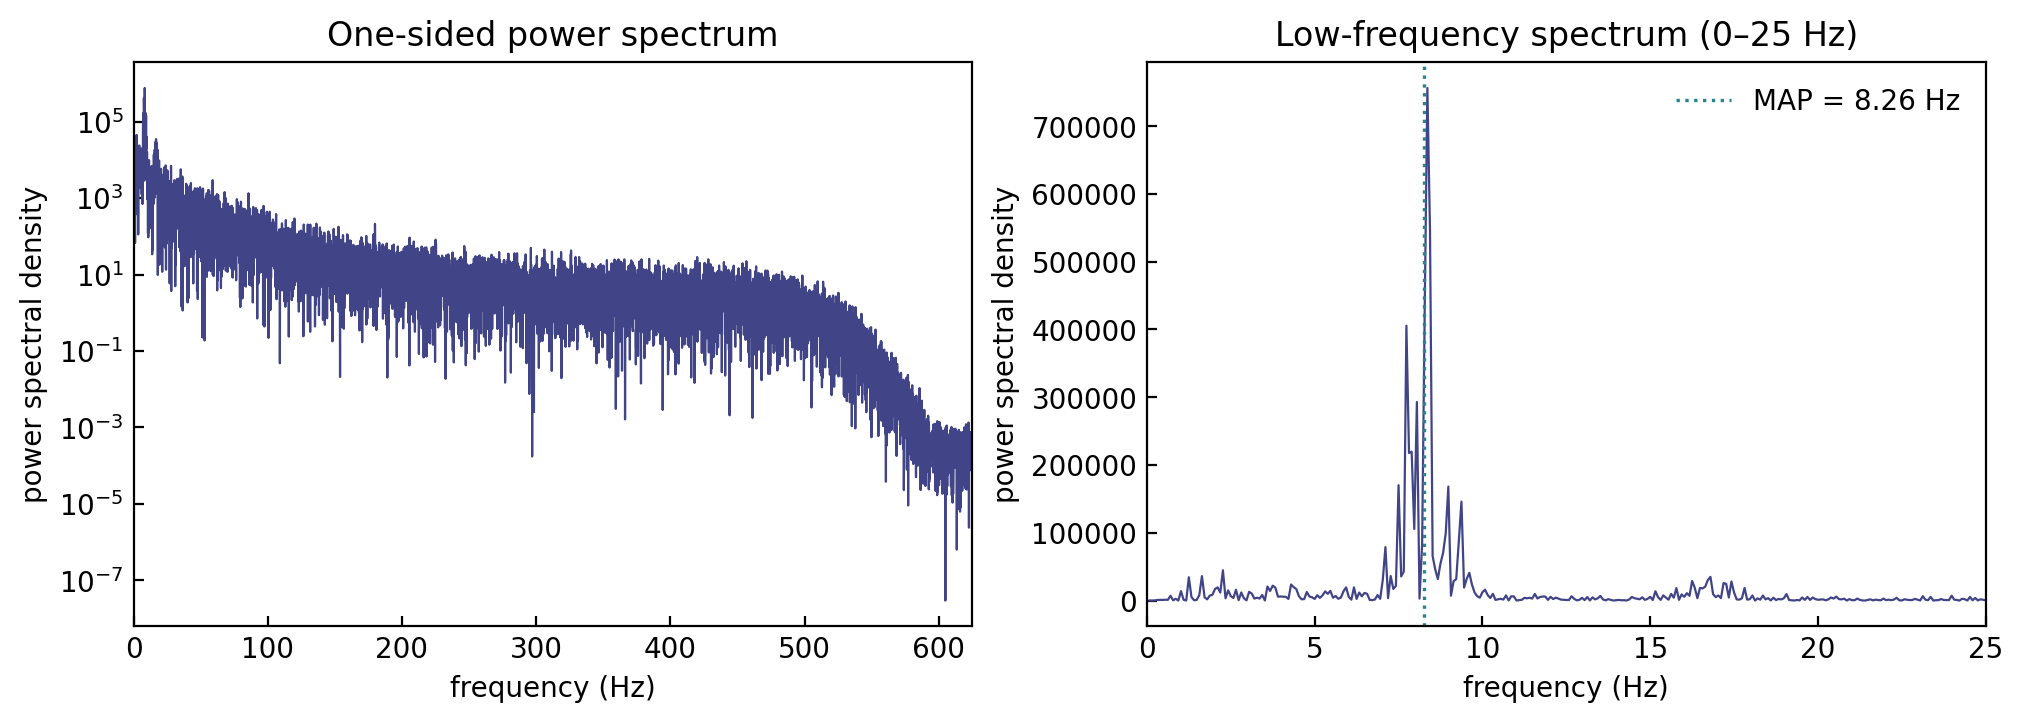

In [6]:
fig, axes = plt.subplots(1, 2, figsize=(10, 3.5), constrained_layout=True)

axes[0].semilogy(frequencies[1:], power_spectrum[1:], color=cmap(0.2), lw=0.8)
axes[0].set(
    xlabel='frequency (Hz)',
    ylabel='power spectral density',
    title='One-sided power spectrum',
    xlim=(0, sampling_frequency / 2),
)

max_frequency = 25.0
frequency_mask = (frequencies > 0) & (frequencies <= max_frequency)
axes[1].plot(
    frequencies[frequency_mask],
    power_spectrum[frequency_mask],
    color=cmap(0.2),
    lw=0.8,
)
# axes[1].axvline(
#     peak_frequency,
#     color=cmap(0.7),
#     ls='--',
#     lw=1,
#     label=rf'FFT peak = {peak_frequency:.2f} Hz',
# )
axes[1].axvline(
    map_frequency,
    color=cmap(0.45),
    ls=':',
    lw=1.2,
    label=rf'MAP = {map_frequency:.2f} Hz',
)
axes[1].set(
    xlabel='frequency (Hz)',
    ylabel='power spectral density',
    title=f'Low-frequency spectrum (0–{max_frequency:g} Hz)',
    xlim=(0, max_frequency),
)
axes[1].legend(frameon=False)

for ax in axes:
    ax.tick_params(direction='in')

plt.show()

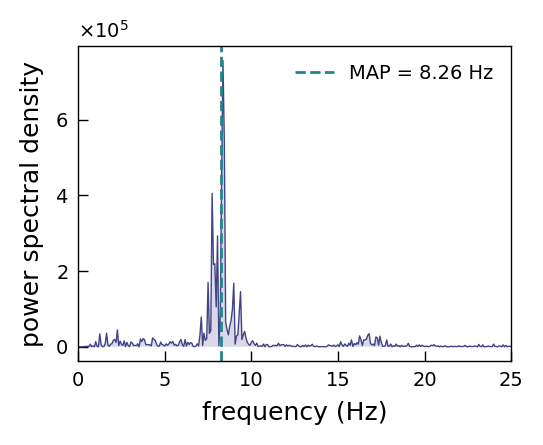

In [7]:
# fixed axis geometry
ax_h = 4.0 * cm
ax_w = 5.5 * cm

left = 1.5 * cm
bottom = 1.5 * cm
right = 0.5 * cm
top = 0.5 * cm

fig_w = left + ax_w + right
fig_h = bottom + ax_h + top

fig = plt.figure(figsize=(fig_w, fig_h))

ax = fig.add_axes([
    left / fig_w,
    bottom / fig_h,
    ax_w / fig_w,
    ax_h / fig_h
])

max_frequency = 25.0
frequency_mask = (frequencies > 0) & (frequencies <= max_frequency)
ax.plot(
    frequencies[frequency_mask],
    power_spectrum[frequency_mask],
    color=cmap(0.2),
    lw=0.5,
)
ax.fill(frequencies[frequency_mask], 
        power_spectrum[frequency_mask],
        color=cmap(0.2),
        alpha=0.2,
        lw=0)
ax.axvline(
    map_frequency,
    color=cmap(0.45),
    ls='--',
    lw=1,
    label=rf'MAP = {map_frequency:.2f} Hz',
)
ax.legend(frameon=False, fontsize=7)

formatter = ScalarFormatter(useMathText=True)
formatter.set_scientific(True)
formatter.set_powerlimits((0, 0))

ax.yaxis.set_major_formatter(formatter)
ax.yaxis.get_offset_text().set_fontsize(7)

ax.set_xlim(0, max_frequency)

ax.set_xlabel('frequency (Hz)', fontsize=9)
ax.set_ylabel('power spectral density', fontsize=9)

# Set tick label fonts to 7 pt, tick mark widths to 0.5 pt, and ticks pointing inward
ax.tick_params(axis='both', which='major', labelsize=7, width=0.5, direction='in')
ax.tick_params(axis='both', which='minor', labelsize=7, width=0.5, direction='in')

# Set the width of the frame (all spines) to 0.5 pt
for spine in ax.spines.values():
    spine.set_linewidth(0.5)

## Harmonic fit

The FFT peak remains a spectral estimate, but an apples-to-apples phase comparison requires a common frequency. At the Bayesian MAP frequency $\hat\omega_{\mathrm{MAP}}$, fit

$$y(t)=c+A\cos(\hat\omega_{\mathrm{MAP}}t+\phi_{\mathrm{FFT}})$$

by linear least squares in the equivalent first-harmonic basis.

In [8]:
design_matrix = np.column_stack([
    np.ones_like(tk),
    np.cos(omega_map * tk),
    np.sin(omega_map * tk),
])
offset_hat, cosine_coefficient, sine_coefficient = np.linalg.lstsq(
    design_matrix, yk, rcond=None
)[0]

amplitude_fft = np.hypot(cosine_coefficient, sine_coefficient)
phi_fft = np.arctan2(-sine_coefficient, cosine_coefficient)
theta_fft = omega_map * tk + phi_fft
fitted_signal = offset_hat + amplitude_fft * np.cos(theta_fft)

print(f'Peak frequency:       {peak_frequency:.3f} Hz')
print(f'Common MAP frequency: {omega_map:.3f} rad/s')
print(f'FFT relative phase:   {phi_fft:.3f} rad')
print(f'Harmonic amplitude:   {amplitude_fft:.1f}')
print(f'Constant offset:      {offset_hat:.1f}')

Peak frequency:       8.359 Hz
Common MAP frequency: 51.868 rad/s
FFT relative phase:   -0.270 rad
Harmonic amplitude:   145.9
Constant offset:      -10.5


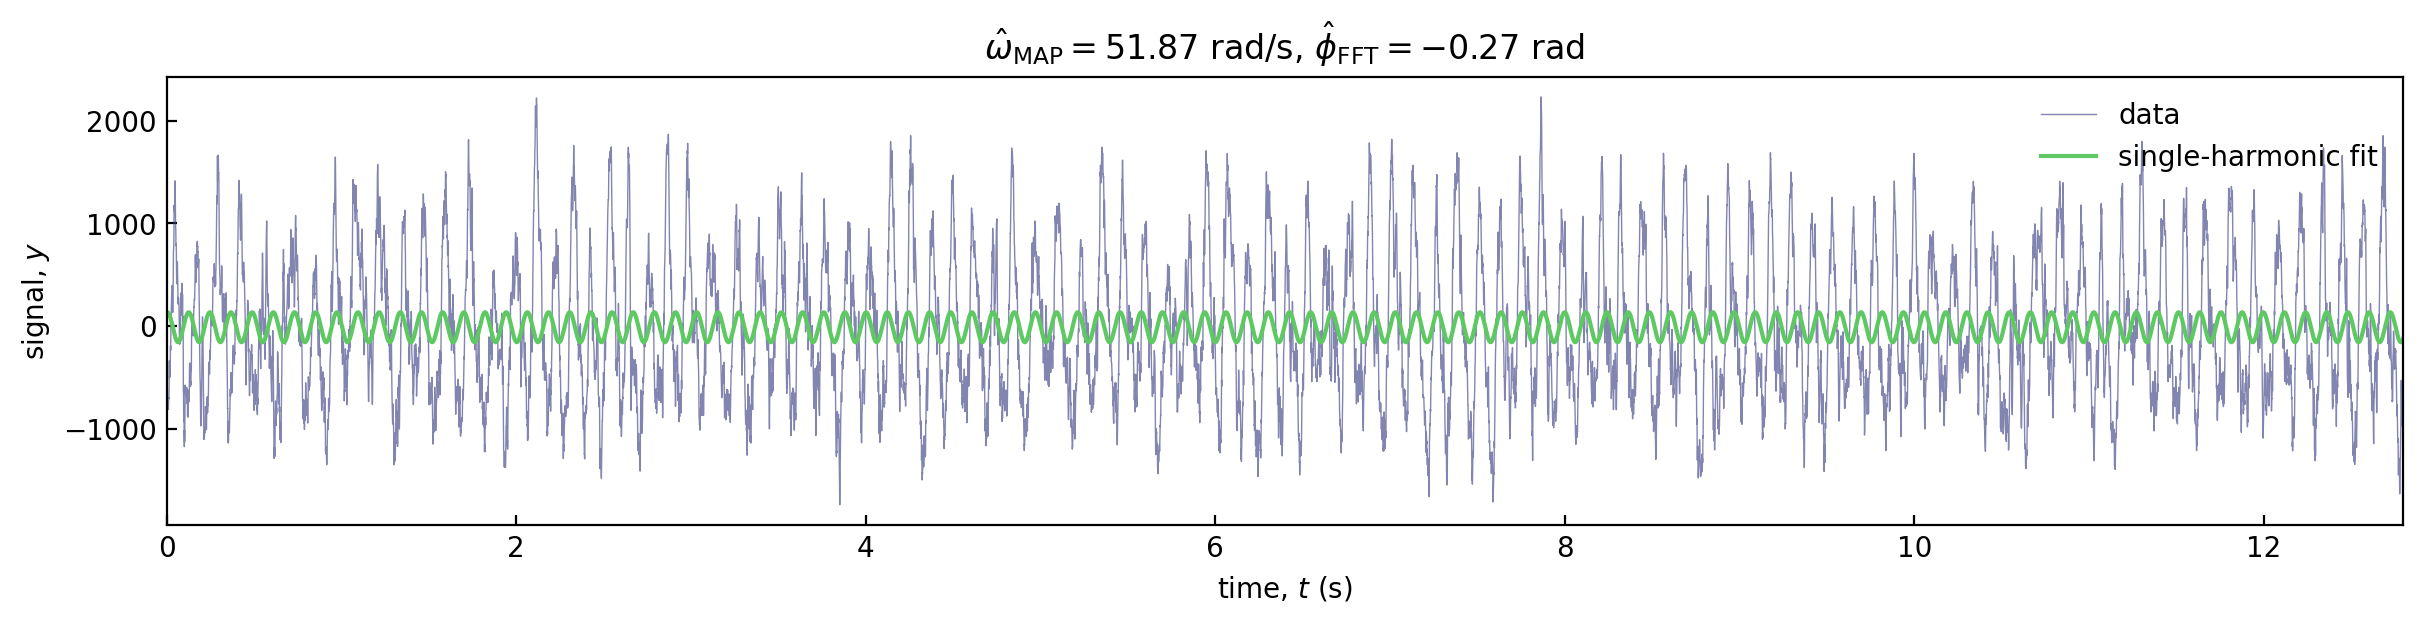

In [9]:
fig, ax = plt.subplots(figsize=(12, 3), constrained_layout=True)
ax.plot(tk, yk, color=cmap(0.2), lw=0.5, alpha=0.65, label='data')
ax.plot(tk, fitted_signal, color=cmap(0.75), lw=1.5, label='single-harmonic fit')

ax.set(
    xlabel='time, $t$ (s)',
    ylabel='signal, $y$',
    title=rf'$\hat{{\omega}}_{{\mathrm{{MAP}}}}={omega_map:.2f}$ rad/s, $\hat{{\phi}}_{{\mathrm{{FFT}}}}={phi_fft:.2f}$ rad',
    xlim=(tk[0], tk[-1]),
)
ax.tick_params(direction='in')
ax.legend(frameon=False)
plt.show()

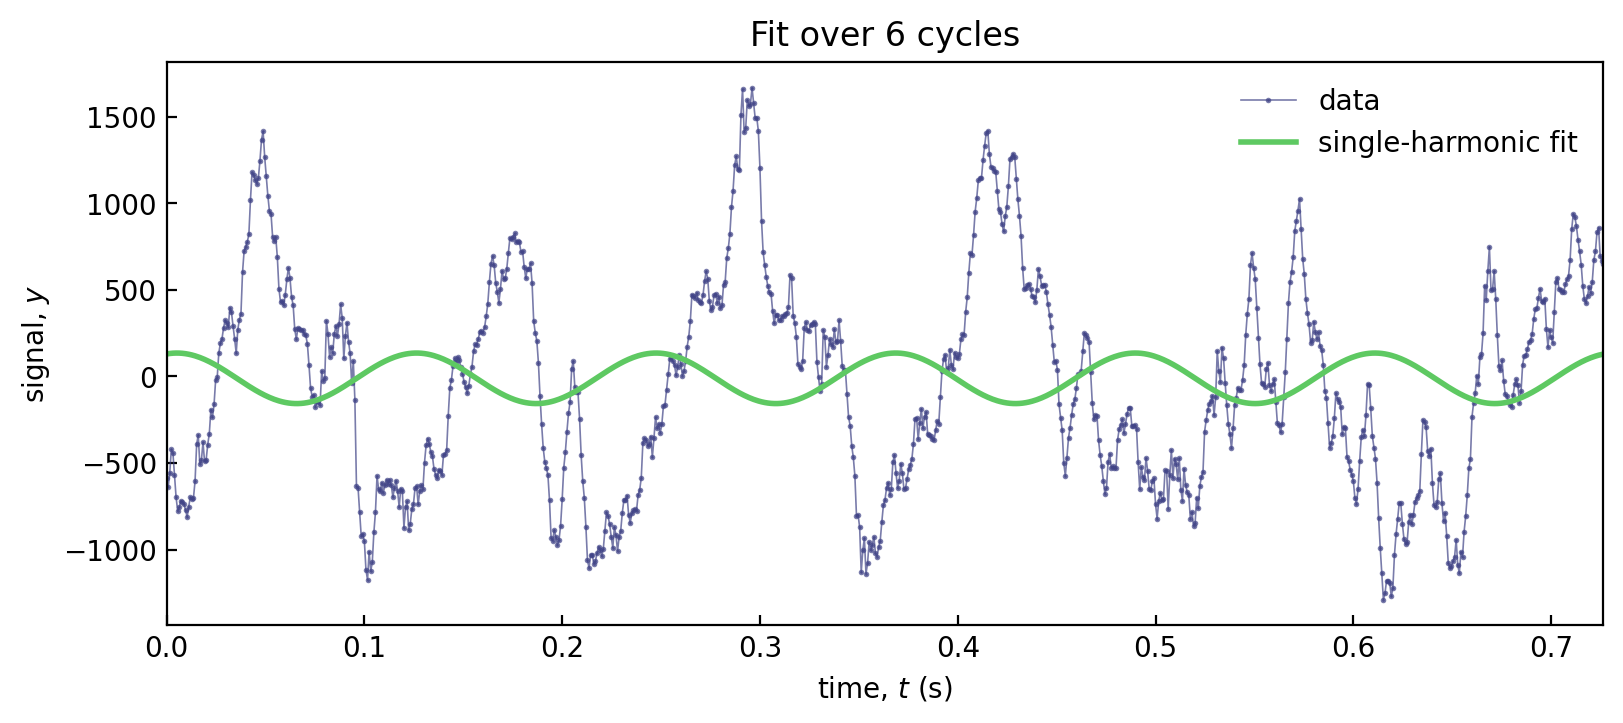

In [10]:
n_cycles = 6
period_map = 2 * np.pi / omega_map
narrow_window = tk <= tk[0] + n_cycles * period_map

fig, ax = plt.subplots(figsize=(8, 3.5), constrained_layout=True)
ax.plot(
    tk[narrow_window],
    yk[narrow_window],
    '.-',
    color=cmap(0.2),
    lw=0.6,
    ms=2,
    alpha=0.7,
    label='data',
)
ax.plot(
    tk[narrow_window],
    fitted_signal[narrow_window],
    color=cmap(0.75),
    lw=2,
    label='single-harmonic fit',
)

ax.set(
    xlabel='time, $t$ (s)',
    ylabel='signal, $y$',
    title=f'Fit over {n_cycles} cycles',
    xlim=(tk[narrow_window][0], tk[narrow_window][-1]),
)
ax.tick_params(direction='in')
ax.legend(frameon=False)
plt.show()

## Hilbert-transform phase

For a real signal $y(t)$, the Hilbert transform supplies a quadrature component $\mathcal{H}[y](t)$. Together they form the **analytic signal**

$$z(t)=y(t)+i\mathcal{H}[y](t)=A(t)e^{i\theta_H(t)},$$

whose argument $\theta_H(t)=\arg z(t)$ is the instantaneous phase. This phase is most meaningful for a narrowband signal, so the EEG is first isolated in the 4–12 Hz theta band with a zero-phase filter. For comparison with our method, subtracting its MAP frequency estimate $\hat\omega_{\mathrm{MAP}}t$ gives the relative phase

$$\phi_H(t)=\operatorname{wrap}\!\left[\theta_H(t)-\hat\omega_{\mathrm{MAP}}t\right],$$

where `wrap` maps angles to $[-\pi,\pi)$.

In [11]:
from scipy.signal import butter, hilbert, sosfiltfilt

theta_band = (4.0, 12.0)  # Hz
theta_filter = butter(
    4,
    theta_band,
    btype='bandpass',
    fs=sampling_frequency,
    output='sos',
)
theta_signal = sosfiltfilt(theta_filter, centered_signal)
analytic_signal = hilbert(theta_signal)

hilbert_phase = np.unwrap(np.angle(analytic_signal))
hilbert_relative_phase_raw = hilbert_phase - omega_map * tk
relative_phase_unwrapped = hilbert_relative_phase_raw
relative_phase = np.angle(np.exp(1j * hilbert_relative_phase_raw))

print(f'MAP frequency from our method: {omega_map:.3f} rad/s')
print(f'                              {omega_map / (2 * np.pi):.3f} Hz')

MAP frequency from our method: 51.868 rad/s
                              8.255 Hz


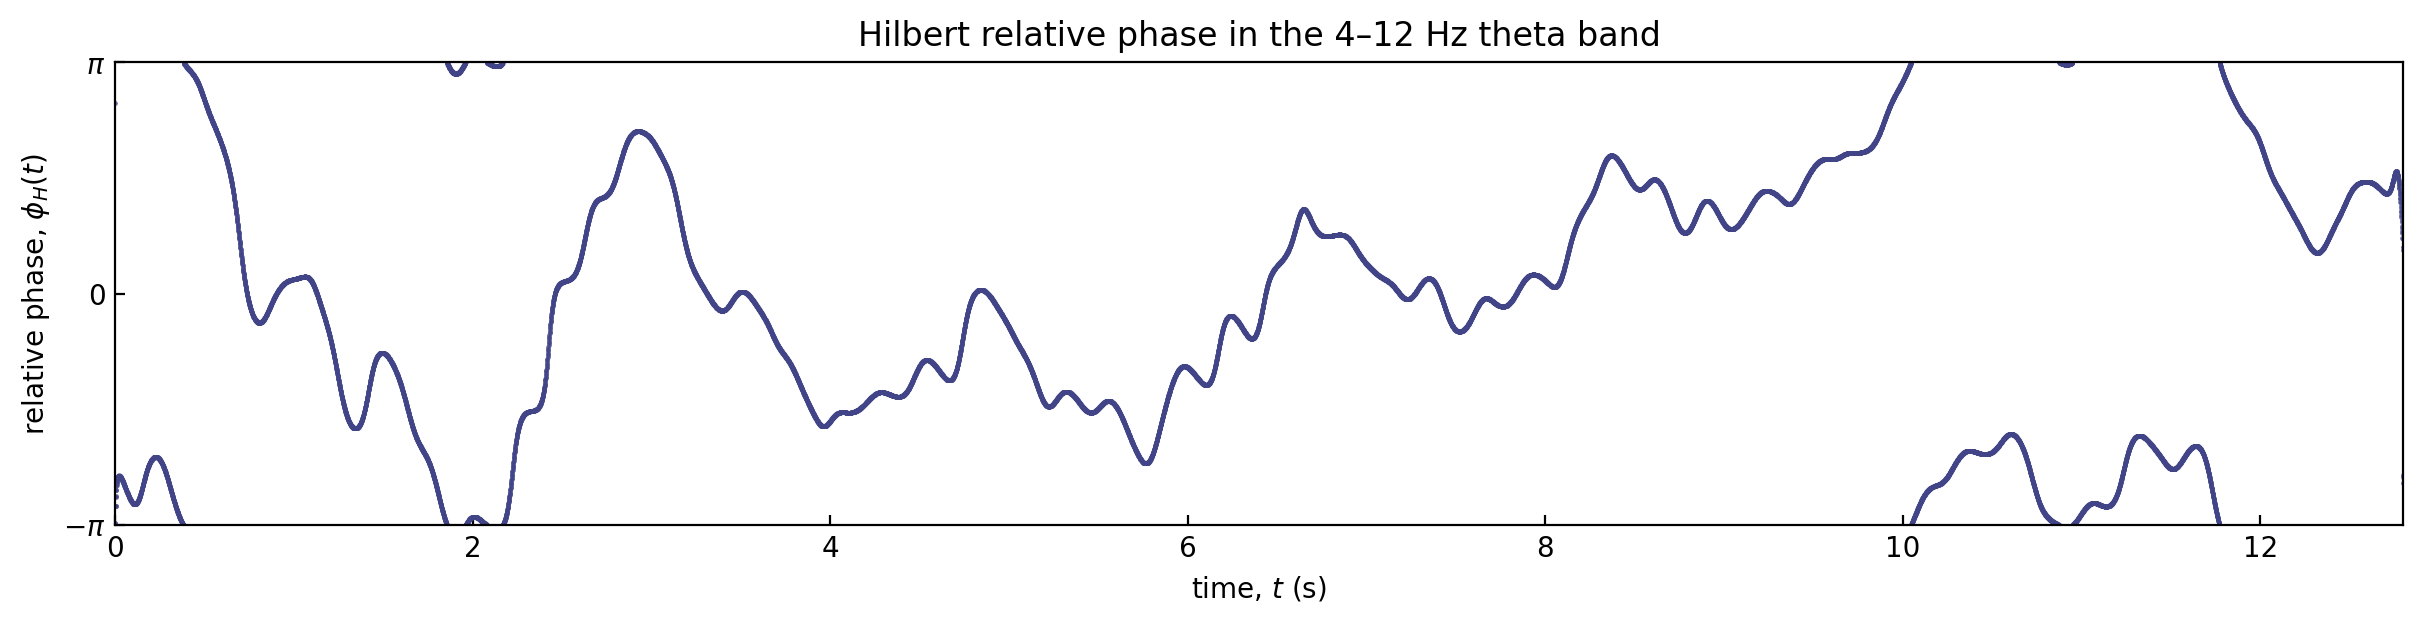

In [12]:
fig, ax = plt.subplots(figsize=(12, 3), constrained_layout=True)
ax.plot(tk, relative_phase, '.', color=cmap(0.2), ms=1.5, alpha=0.7)

ax.set(
    xlabel='time, $t$ (s)',
    ylabel=r'relative phase, $\phi_H(t)$',
    title='Hilbert relative phase in the 4–12 Hz theta band',
    xlim=(tk[0], tk[-1]),
    ylim=(-np.pi, np.pi),
    yticks=(-np.pi, 0, np.pi),
    yticklabels=(r'$-\pi$', '0', r'$\pi$'),
)
ax.tick_params(direction='in')
plt.show()

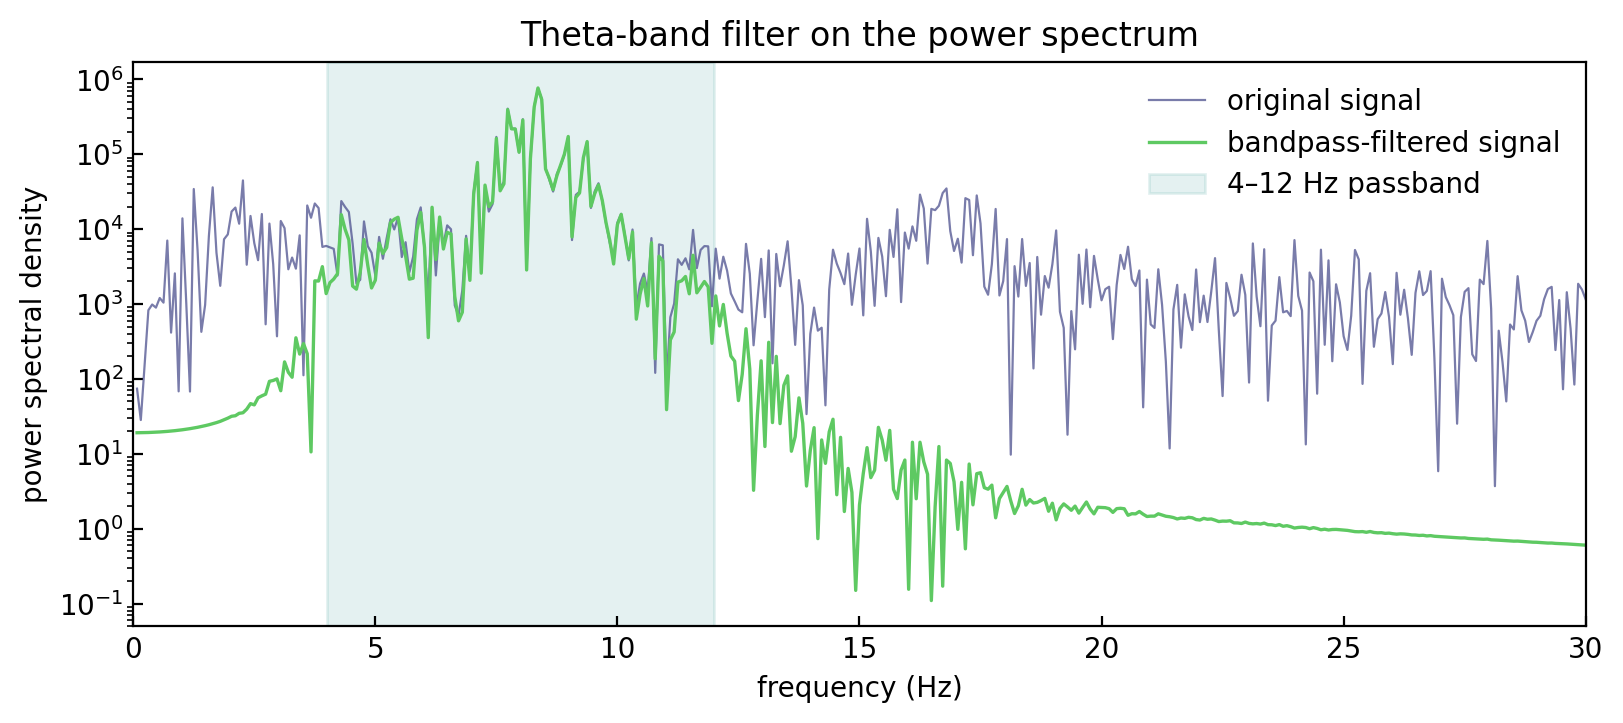

In [13]:
filtered_fft_values = np.fft.rfft(theta_signal)
filtered_power_spectrum = (
    np.abs(filtered_fft_values) ** 2 / (sampling_frequency * theta_signal.size)
)
filtered_power_spectrum[1:-1] *= 2

fig, ax = plt.subplots(figsize=(8, 3.5), constrained_layout=True)
spectrum_window = (frequencies > 0) & (frequencies <= 30)
ax.semilogy(
    frequencies[spectrum_window],
    power_spectrum[spectrum_window],
    color=cmap(0.2),
    lw=0.8,
    alpha=0.7,
    label='original signal',
)
ax.semilogy(
    frequencies[spectrum_window],
    filtered_power_spectrum[spectrum_window],
    color=cmap(0.75),
    lw=1.2,
    label='bandpass-filtered signal',
)
ax.axvspan(*theta_band, color=cmap(0.5), alpha=0.12, label='4–12 Hz passband')

ax.set(
    xlabel='frequency (Hz)',
    ylabel='power spectral density',
    title='Theta-band filter on the power spectrum',
    xlim=(0, 30),
)
ax.tick_params(direction='in')
ax.legend(frameon=False)
plt.show()

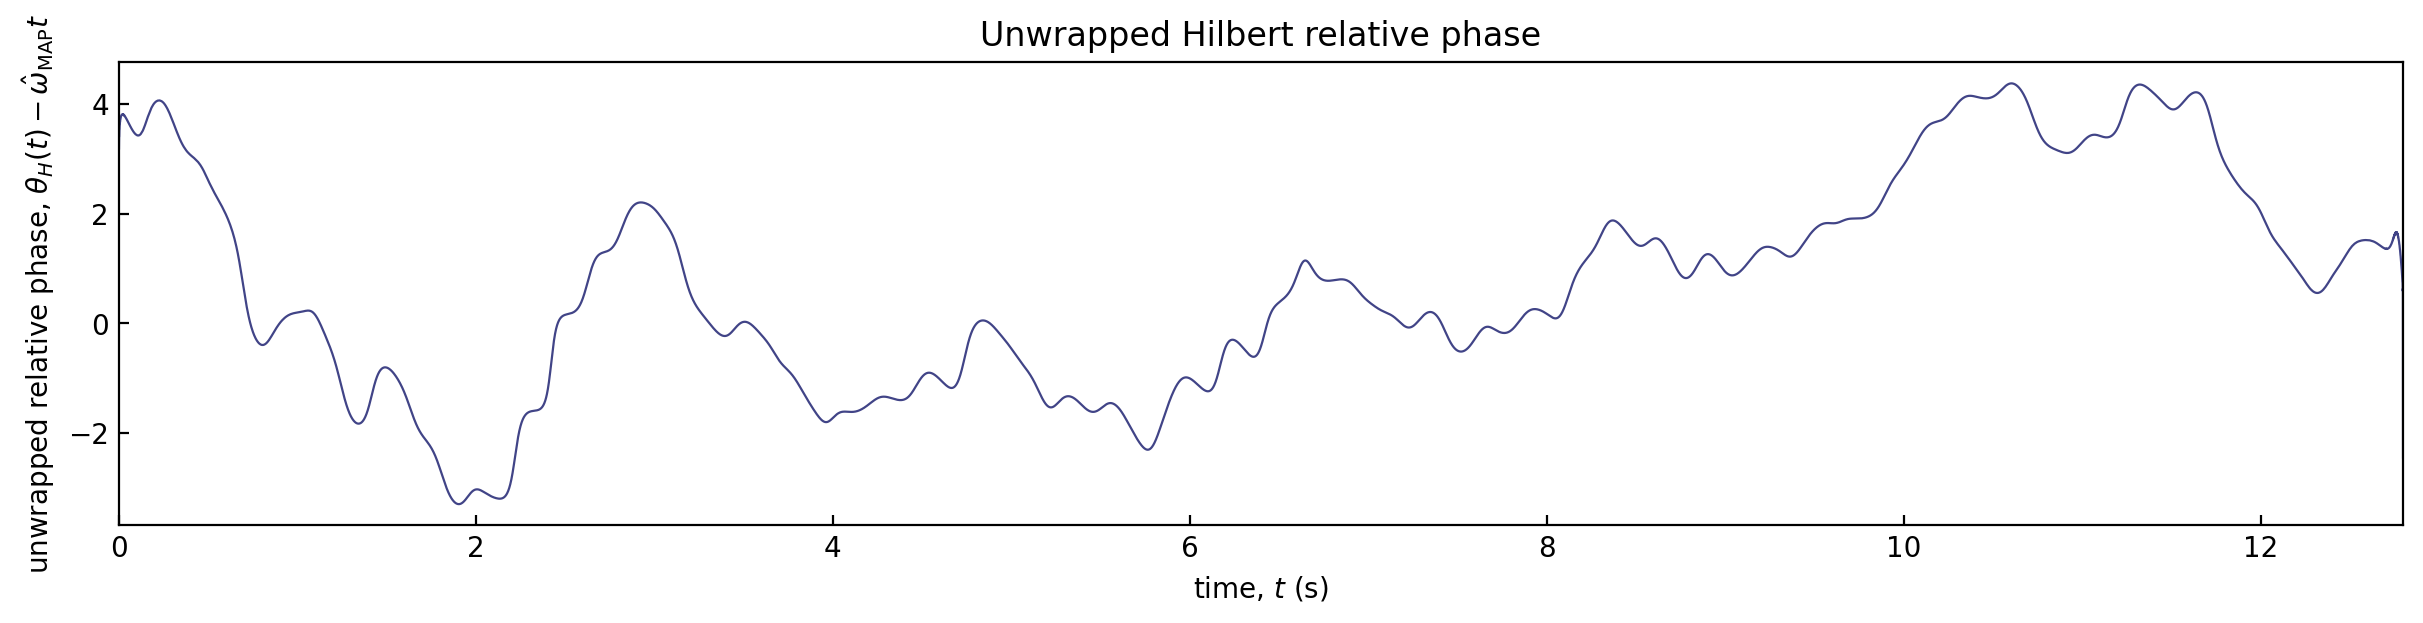

In [14]:
fig, ax = plt.subplots(figsize=(12, 3), constrained_layout=True)
ax.plot(tk, relative_phase_unwrapped, color=cmap(0.2), lw=0.8)

ax.set(
    xlabel='time, $t$ (s)',
    ylabel=r'unwrapped relative phase, $\theta_H(t)-\hat{\omega}_{\mathrm{MAP}}t$',
    title='Unwrapped Hilbert relative phase',
    xlim=(tk[0], tk[-1]),
)
ax.tick_params(direction='in')
plt.show()

## Comparison to Our Method

The saved Bayesian result reports the posterior mean and interquartile interval of the unwrapped relative phase on every fourth sample. All methods below use the same MAP frequency. Two phase-origin conventions are compared:

1. **First-harmonic gauge:** Regress the signal against $1$, $\cos\theta$, and $\sin\theta$, then rotate each raw phase by $\delta=\operatorname{atan2}(-B_{1,\mathrm{raw}},A_{1,\mathrm{raw}})$. This imposes $B_1=0$ and $A_1>0$, matching the gauge used by the Bayesian waveform; higher Bayesian harmonics do not affect this gauge.
2. **Shared fitted shift:** Estimate one inverse-variance-weighted offset between the raw Hilbert relative phase and the inferred phase, then apply that same offset to both the Hilbert trajectory and the constant FFT phase.

In [15]:
inference_path = '../Hippocampal/data/phi_inf_data_good.npz'
with np.load(inference_path) as inference_data:
    inference_time = inference_data['tk']
    inferred_phase_mean = inference_data['phi_inf_mean']
    inferred_phase_lo = inference_data['phi_inf_lo']
    inferred_phase_hi = inference_data['phi_inf_hi']

# Convert the Gaussian-equivalent IQR to variance.
normal_quartile = 0.6744897501960817
inferred_phase_std = (
    (inferred_phase_hi - inferred_phase_lo) / (2 * normal_quartile)
)
inferred_phase_variance = inferred_phase_std**2
phase_alignment_weights = 1 / inferred_phase_variance

def fit_first_harmonic_gauge(signal, raw_phase):
    """Fit and gauge-fix a one-harmonic waveform."""
    basis = np.column_stack([
        np.ones_like(raw_phase),
        np.cos(raw_phase),
        np.sin(raw_phase),
    ])
    offset, A1_raw, B1_raw = np.linalg.lstsq(basis, signal, rcond=None)[0]
    delta = np.arctan2(-B1_raw, A1_raw)
    A1 = A1_raw * np.cos(delta) - B1_raw * np.sin(delta)
    B1 = A1_raw * np.sin(delta) + B1_raw * np.cos(delta)
    return offset, A1_raw, B1_raw, delta, A1, B1

# Approach 1: impose the first-harmonic waveform gauge independently.
fft_gauge_fit = fit_first_harmonic_gauge(yk, omega_map * tk)
hilbert_gauge_fit = fit_first_harmonic_gauge(yk, hilbert_phase)
delta_fft = fft_gauge_fit[3]
delta_hilbert = hilbert_gauge_fit[3]

hilbert_phase_gauge = hilbert_phase + delta_hilbert - omega_map * tk
hilbert_phase_gauge_grid = np.interp(inference_time, tk, hilbert_phase_gauge)

# Select only the equivalent 2*pi branch closest at the initial time.
hilbert_branch_shift = 2 * np.pi * np.round(
    (inferred_phase_mean[0] - hilbert_phase_gauge_grid[0]) / (2 * np.pi)
)
fft_branch_shift = 2 * np.pi * np.round(
    (inferred_phase_mean[0] - delta_fft) / (2 * np.pi)
) - 2 * np.pi
hilbert_phase_gauge_grid += hilbert_branch_shift
fft_phase_gauge = np.full_like(inference_time, delta_fft + fft_branch_shift)

# Approach 2: fit one Hilbert offset and apply it to both cosine-origin phases.
hilbert_phase_on_inference_grid = np.interp(
    inference_time, tk, hilbert_relative_phase_raw
)
phase_origin_shift = np.average(
    inferred_phase_mean - hilbert_phase_on_inference_grid,
    weights=phase_alignment_weights,
)
hilbert_phase_aligned = hilbert_phase_on_inference_grid + phase_origin_shift
fft_phase_aligned = np.full_like(inference_time, phi_fft + phase_origin_shift)

print(f'FFT gauge shift:       {delta_fft:.3f} rad')
print(f'Hilbert gauge shift:   {delta_hilbert:.3f} rad')
print(f'Shared fitted shift:   {phase_origin_shift:.3f} rad')
print(f'Rotated FFT B1:        {fft_gauge_fit[5]:.3e}')
print(f'Rotated Hilbert B1:    {hilbert_gauge_fit[5]:.3e}')

FFT gauge shift:       -0.270 rad
Hilbert gauge shift:   -0.004 rad
Shared fitted shift:   -0.191 rad
Rotated FFT B1:        -7.105e-15
Rotated Hilbert B1:    4.441e-16


In [16]:
from pathlib import Path

hilbert_export_path = Path('data/hilbert_relative_phase_b1_zero.npz')
hilbert_export_path.parent.mkdir(parents=True, exist_ok=True)
np.savez(
    hilbert_export_path,
    time=tk,
    relative_phase=hilbert_phase_gauge,
    fourier_phase=np.asarray(delta_fft),
    omega_map=np.asarray(omega_map),
    gauge_shift=np.asarray(delta_hilbert),
    filter_order=np.asarray(4),
    filter_band_hz=np.asarray(theta_band),
)
print(f'Saved Hilbert B1=0 relative phase to {hilbert_export_path}')

Saved Hilbert B1=0 relative phase to data/hilbert_relative_phase_b1_zero.npz


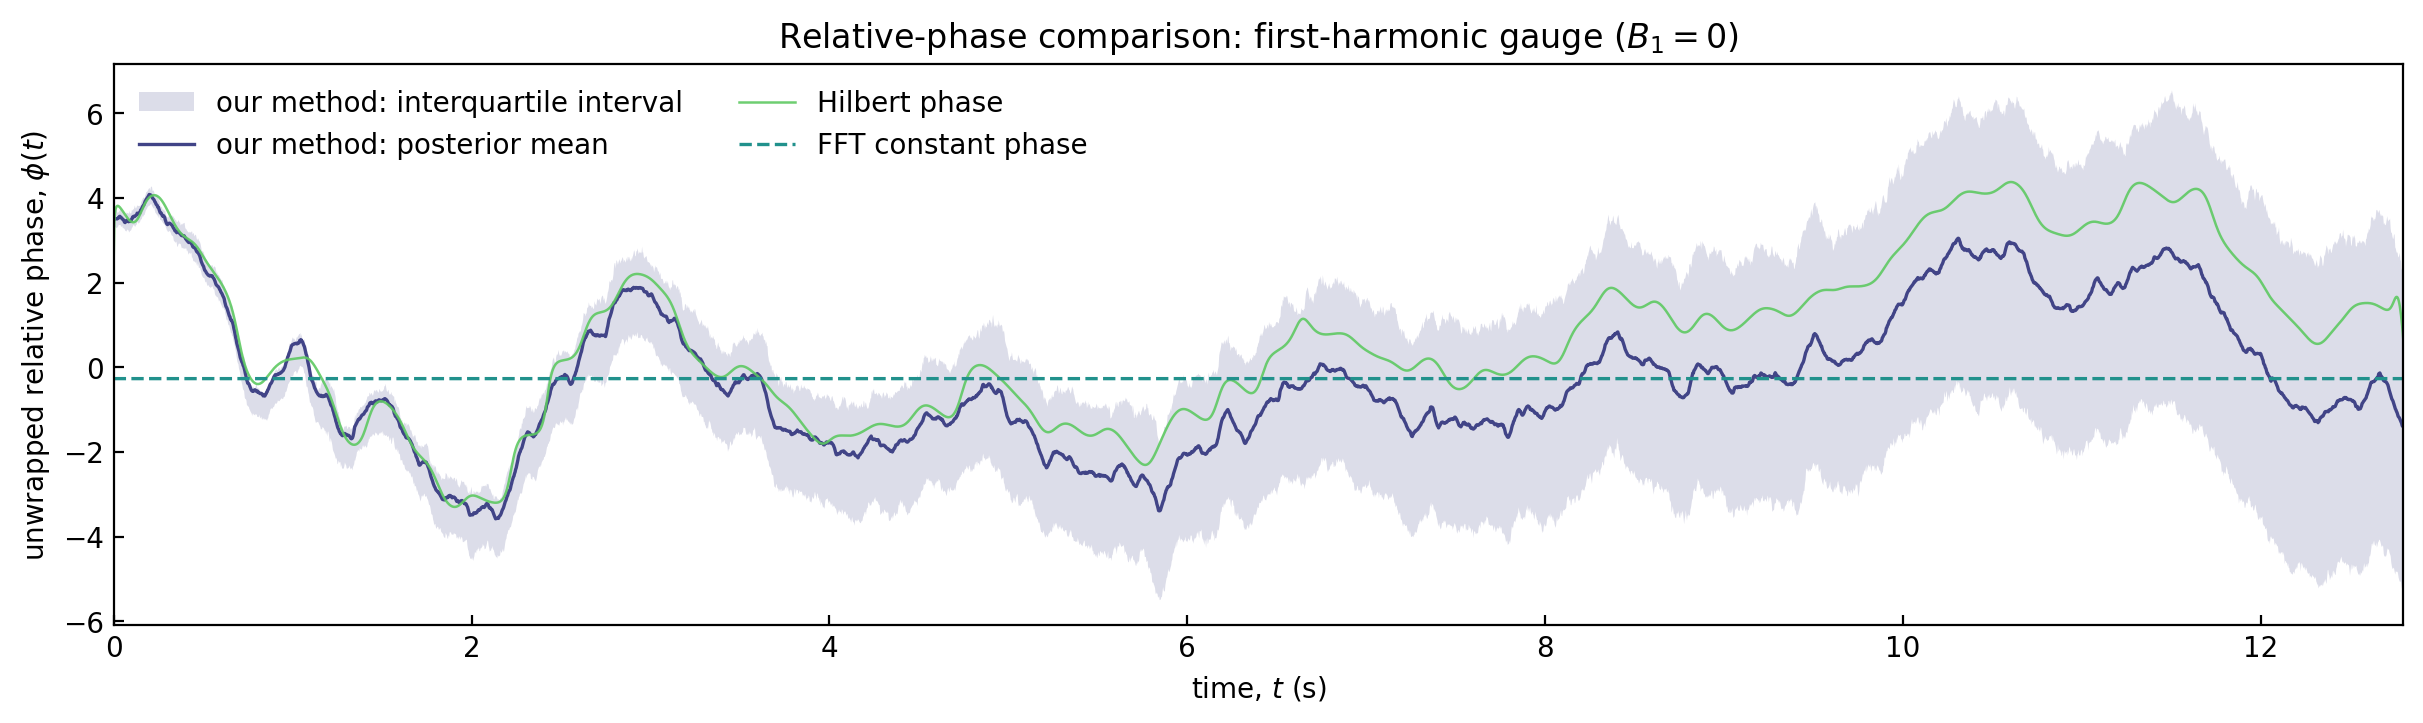

In [17]:
fig, ax = plt.subplots(figsize=(12, 3.5), constrained_layout=True)
ax.fill_between(
    inference_time,
    inferred_phase_lo,
    inferred_phase_hi,
    lw=0.0,
    color=cmap(0.2),
    alpha=0.18,
    label='our method: interquartile interval',
)
ax.plot(
    inference_time,
    inferred_phase_mean,
    color=cmap(0.2),
    lw=1.2,
    label='our method: posterior mean',
)
ax.plot(
    inference_time,
    hilbert_phase_gauge_grid,
    color=cmap(0.75),
    lw=0.9,
    alpha=0.9,
    label='Hilbert phase',
)
ax.plot(
    inference_time,
    fft_phase_gauge,
    color=cmap(0.5),
    lw=1.2,
    ls='--',
    label='FFT constant phase',
)

ax.set(
    xlabel='time, $t$ (s)',
    ylabel=r'unwrapped relative phase, $\phi(t)$',
    title=r'Relative-phase comparison: first-harmonic gauge ($B_1=0$)',
    xlim=(inference_time[0], inference_time[-1]),
)
ax.tick_params(direction='in')
ax.legend(frameon=False, ncol=2)
plt.show()

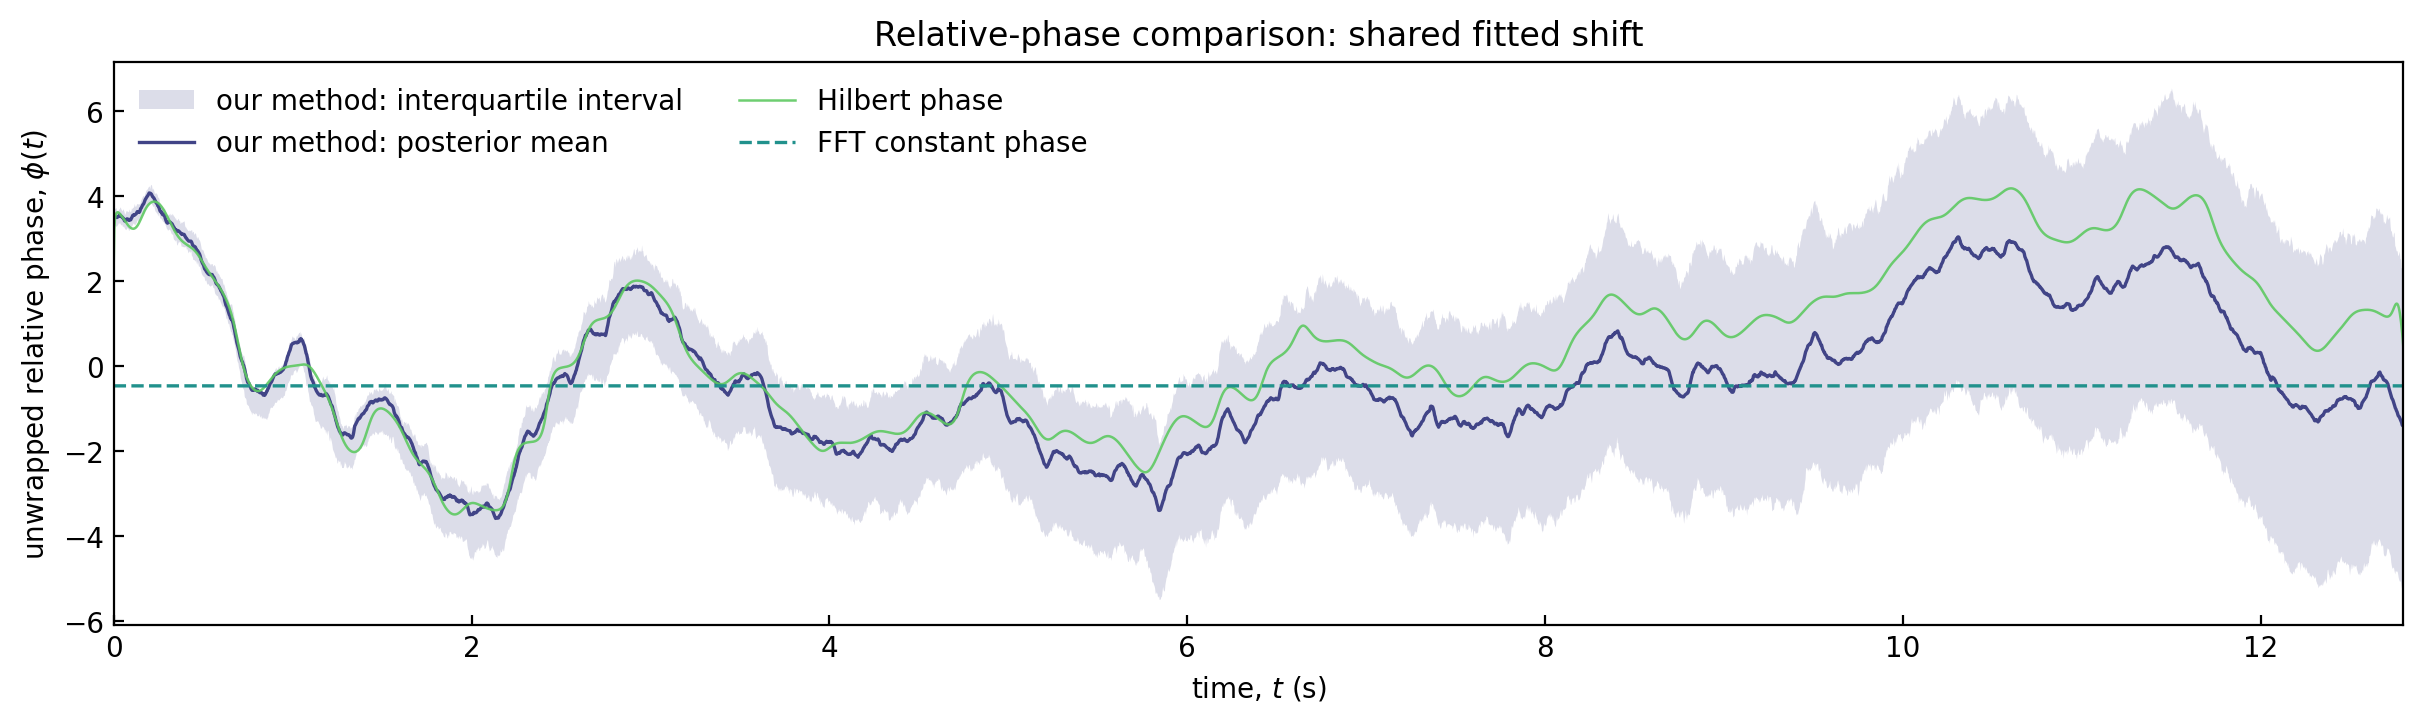

In [18]:
fig, ax = plt.subplots(figsize=(12, 3.5), constrained_layout=True)
ax.fill_between(
    inference_time,
    inferred_phase_lo,
    inferred_phase_hi,
    lw=0.0,
    color=cmap(0.2),
    alpha=0.18,
    label='our method: interquartile interval',
)
ax.plot(
    inference_time,
    inferred_phase_mean,
    color=cmap(0.2),
    lw=1.2,
    label='our method: posterior mean',
)
ax.plot(
    inference_time,
    hilbert_phase_aligned,
    color=cmap(0.75),
    lw=0.9,
    alpha=0.9,
    label='Hilbert phase',
)
ax.plot(
    inference_time,
    fft_phase_aligned,
    color=cmap(0.5),
    lw=1.2,
    ls='--',
    label='FFT constant phase',
)

ax.set(
    xlabel='time, $t$ (s)',
    ylabel=r'unwrapped relative phase, $\phi(t)$',
    title='Relative-phase comparison: shared fitted shift',
    xlim=(inference_time[0], inference_time[-1]),
)
ax.tick_params(direction='in')
ax.legend(frameon=False, ncol=2)
plt.show()